# 5 · Incoherent noise and the ceiling

*Roadmap:* [1 · Teleportation](01_teleportation.ipynb) → [2 · Channel noise](02_channel_noise.ipynb) → [3 · Correction from counts](03_correction_from_counts.ipynb) → [4 · Automatic recalibration](04_automatic_recalibration.ipynb) → **5 · Incoherent noise and the ceiling** → [6 · Correlated noise](06_correlated_noise.ipynb) → [7 · Efficient learning and tracking](07_efficient_learning_and_tracking.ipynb) → [8 · Real hardware](08_real_hardware.ipynb)

**Question.** Real channels also lose energy and phase: incoherent noise, which no unitary can undo (notebook 2).
With such noise F = 1 is out of reach. What is the **best possible** fidelity, and does the counts-only calibrator
reach it?

**The channel.** On each channel qubit: first the coherent rotation N1, then an incoherent part of strength p on q2
and 1.5 p on q3, from one of three families:

| family | incoherent part | physical picture |
|---|---|---|
| D | depolarizing p | white noise |
| A | amplitude damping p | energy loss (T1) |
| M | amplitude damping p/2 + dephasing p | T1 and T2 together, the typical device |

In [1]:
import sys
try:
    import telecorr
except ImportError:                       # running from a source checkout without installation
    sys.path.insert(0, "../src"); import telecorr

import numpy as np
import matplotlib.pyplot as plt
from telecorr import protocol as P, channels as C, calibrate as K, probes as Pr
from telecorr.ceiling import ceiling
from telecorr.rotations import correction_rotations, NOMINAL_NOISE
from telecorr.states import MESSAGES, message_state
from telecorr.twirl import f_avg_of
from telecorr.reference import number
from telecorr.plotting import use_style, CONDITION, INK_2
from telecorr.report import md_table, show
use_style()
MSG = [message_state(n) for n in MESSAGES]

## The model: the twirl in transfer-matrix form, and the ceiling

Each leg of the channel is described by its 3 × 3 transfer matrix T = D R: the rotation R, then the incoherent
shrink D. A correction with rotation R_V gives Bob the Pauli channel with shrink factors diag(R_V T) (Theorem T5.2),
whatever the noise, non-unital included. Alice's random outcomes average away any pull towards |0⟩:

In [2]:
g = 0.3
legs = {2: C.incoherent_kraus(amp=g), 3: C.incoherent_kraus(amp=1.5 * g)}
rows = []
for name in ("|00>", "|11>"):
    psi = message_state("|00>") if name == "|00>" else np.eye(4)[3]
    direct = (1.0 if name == "|00>" else (1 - g) * (1 - 1.5 * g))
    rows.append((name, direct, P.fidelity(psi, P.teleport(psi, legs=legs)["bob"])))
show(md_table(rows, ["message", f"F, amplitude damping ({g} / {1.5 * g:.2f}) applied directly", "F, teleported through the damped channel"], 4))

| message | F, amplitude damping (0.3 / 0.45) applied directly | F, teleported through the damped channel |
|---|---|---|
| |00> | 1.0000 | 0.6587 |
| |11> | 0.3850 | 0.6587 |

Every message is therefore governed by p_I = (1 + tr(R_V T))/4 on each leg, and F_avg = (4 p_I^(q2) p_I^(q3) + 1)/5.
Maximising tr(R_V T) over rotations is the orthogonal **Procrustes** problem, solved in closed form by the singular
value decomposition of T. Its maximum is the **ceiling**: no correction can do better (Theorem T5.6). For the
three families here the incoherent part is symmetric with non-negative entries, so the ceiling is reached by the
exact inverse of the rotation. The remaining loss is unavoidable.

The probe cost is still pinned to F_avg for any local channel (Theorem T5.9), but its minimum is no longer exactly
the ceiling under non-depolarizing noise. This **probe bias** is real but only second order (Proposition P5.10):

In [3]:
from scipy.optimize import minimize
T = C.leg_T(None, "A", 0.3)
x0, Fc = ceiling(T)
best = min((minimize(lambda x: Pr.cost(x, T), x0 + np.random.default_rng(k).normal(0, 0.05, 6), method="BFGS", options={"gtol": 1e-12})
            for k in range(4)), key=lambda r: r.fun)
show(f"Amplitude damping, p = 0.3: the minimum of the probe cost lies {Fc - f_avg_of(correction_rotations(best.x), T):.1e} below the "
     "ceiling in F_avg. This is far below the shot noise of any calibration.")

Amplitude damping, p = 0.3: the minimum of the probe cost lies 1.2e-06 below the ceiling in F_avg. This is far below the shot noise of any calibration.

## The method: Rotosolve in local coordinates

Every angle of the correction enters the probe cost as an **exact sinusoid** a + b cos t + c sin t. Three
measured costs (at t and t ± π/2) fix it, and the step jumps straight to its minimum (Proposition P5.15). The
coordinates are *local* around the current correction, V = V_ref Rz(a) Ry(b) Rx(c) on each qubit, which are well
conditioned everywhere (the U(θ, φ, λ) angles are not, near θ = 0 and π). A phase ends when a whole sweep no
longer lowers the measured cost by more than two standard deviations of its shot noise. The calibrator
(`calibrate.RelativeAutoCalibrator`) adapts the trigger and stop rule of notebook 4 to a floor below 1: it fires on
a significant *change* of the monitored P(00), and stops the multi-start search when two starts agree.

## Result: the calibrator against the ceiling

At every point a *fresh* calibrator (no knowledge of the noise) calibrates from counts. For comparison, the
COBYLA method of notebook 4 runs on the same channels.

In [4]:
ps = (0.0, 0.05, 0.1, 0.2, 0.3)
rows, pts = [], []
for fam in C.FAMILIES:
    for k, p in enumerate(ps):
        T = C.leg_T(None, fam, p)
        Fc = ceiling(T)[1]
        Fn = f_avg_of(correction_rotations(None), T)
        roto = K.RelativeAutoCalibrator(K.ProbeSampler(T, np.random.default_rng(500 + 10 * k + len(rows))), seed=11 + k)
        i5 = roto.recalibrate()
        cob = K.AutoCalibrator(K.ProbeSampler(T, np.random.default_rng(900 + 10 * k + len(rows))), seed=11 + k)
        i4 = cob.recalibrate()
        F5, F4 = K.scores(roto.params, T, MSG)["F_avg"], K.scores(cob.params, T, MSG)["F_avg"]
        rows.append((fam, p, Fn, Fc, F5, Fc - F5, i5["shots"] / 1e6, Fc - F4, i4["shots"] / 1e6))
        pts.append((fam, p, F5))
show(md_table([(f, f"{p:.2f}", f"{a:.4f}", f"{c:.5f}", f"{r:.5f}", f"{g5:.1e}", f"{s5:.1f}", f"{g4:.1e}", f"{s4:.1f}")
               for f, p, a, c, r, g5, s5, g4, s4 in rows],
              ["family", "p", "F_avg, no correction", "ceiling", "Rotosolve calibrator", "gap to the ceiling", "M shots",
               "COBYLA (notebook 4): gap", "M shots"]))
g5, g4 = [r[5] for r in rows], [r[7] for r in rows]
show(f"Rotosolve: largest gap **{max(g5):.1e}** (the study's run: {number('n0017')}), median {np.median([r[6] for r in rows]):.1f} M shots. "
     f"COBYLA: largest gap {max(g4):.1e}, median {np.median([r[8] for r in rows]):.1f} M shots.")

| family | p | F_avg, no correction | ceiling | Rotosolve calibrator | gap to the ceiling | M shots | COBYLA (notebook 4): gap | M shots |
|---|---|---|---|---|---|---|---|---|
| D | 0.00 | 0.6760 | 1.00000 | 1.00000 | 1.2e-06 | 8.4 | 1.4e-04 | 20.7 |
| D | 0.05 | 0.6377 | 0.92669 | 0.92669 | 2.2e-06 | 8.7 | 1.4e-03 | 27.5 |
| D | 0.10 | 0.6010 | 0.85675 | 0.85674 | 8.5e-06 | 8.8 | 2.4e-03 | 23.1 |
| D | 0.20 | 0.5323 | 0.72700 | 0.72699 | 1.3e-05 | 8.8 | 5.0e-03 | 20.8 |
| D | 0.30 | 0.4701 | 0.61075 | 0.61074 | 6.6e-06 | 8.7 | 1.0e-02 | 21.7 |
| A | 0.00 | 0.6760 | 1.00000 | 1.00000 | 1.4e-06 | 8.4 | 4.6e-04 | 21.5 |
| A | 0.05 | 0.6518 | 0.95034 | 0.95034 | 1.5e-06 | 8.7 | 5.0e-03 | 24.2 |
| A | 0.10 | 0.6277 | 0.90136 | 0.90136 | 1.0e-06 | 8.8 | 2.4e-03 | 26.4 |
| A | 0.20 | 0.5799 | 0.80532 | 0.80531 | 4.9e-06 | 9.8 | 5.0e-03 | 23.7 |
| A | 0.30 | 0.5322 | 0.71160 | 0.71159 | 9.5e-06 | 8.8 | 5.9e-03 | 23.2 |
| M | 0.00 | 0.6760 | 1.00000 | 1.00000 | 5.0e-06 | 8.4 | 8.6e-04 | 24.4 |
| M | 0.05 | 0.6493 | 0.95065 | 0.95064 | 5.2e-06 | 14.1 | 7.1e-04 | 24.9 |
| M | 0.10 | 0.6233 | 0.90257 | 0.90257 | 3.6e-06 | 8.8 | 1.1e-03 | 21.9 |
| M | 0.20 | 0.5731 | 0.81019 | 0.81019 | 4.5e-06 | 8.8 | 3.4e-03 | 23.7 |
| M | 0.30 | 0.5251 | 0.72261 | 0.72261 | 1.2e-06 | 8.7 | 2.7e-03 | 22.2 |

Rotosolve: largest gap **1.3e-05** (the study's run: 9.3e-06), median 8.8 M shots. COBYLA: largest gap 1.0e-02, median 23.2 M shots.

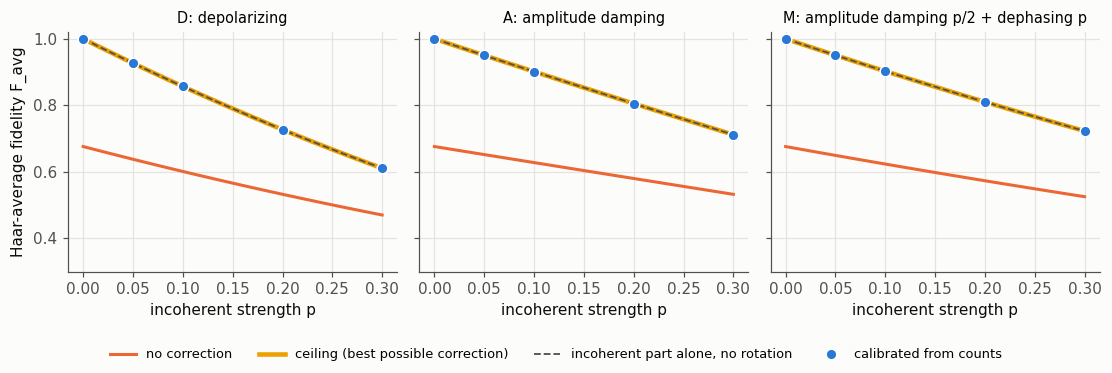

In [5]:
pp = np.linspace(0, 0.3, 31)
fig, axs = plt.subplots(1, 3, figsize=(10.2, 3.4), sharey=True)
for ax, fam in zip(axs, C.FAMILIES):
    none = [f_avg_of(correction_rotations(None), C.leg_T(None, fam, p)) for p in pp]
    ceil = [ceiling(C.leg_T(None, fam, p))[1] for p in pp]
    incoh = [f_avg_of(correction_rotations(None), C.leg_T({q: dict(c, angle=0.0) for q, c in NOMINAL_NOISE.items()}, fam, p)) for p in pp]
    ax.plot(pp, none, color=CONDITION["no correction"], label="no correction")
    ax.plot(pp, ceil, color=CONDITION["ceiling"], lw=3, label="ceiling (best possible correction)")
    ax.plot(pp, incoh, color=INK_2, ls="--", lw=1.2, label="incoherent part alone, no rotation")
    ax.plot([p for f, p, _ in pts if f == fam], [F for f, _, F in pts if f == fam], "o", color=CONDITION["learned from counts"],
            mec="white", ms=7, label="calibrated from counts")
    ax.set_title(f"{fam}: {C.FAMILIES[fam][0]}", fontsize=9.5); ax.set_xlabel("incoherent strength p")
axs[0].set_ylabel("Haar-average fidelity F_avg"); axs[0].set_ylim(0.3, 1.02)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, fontsize=8.5); plt.tight_layout(rect=(0, 0.09, 1, 1)); plt.show()

The calibrator lands on the ceiling, which here coincides with "incoherent part alone": it removes the whole
coherent error and nothing more can be removed.

## Result: the realistic demo channel (M, p = 0.1)

In [6]:
T = C.leg_T(None, "M", 0.1)
cal = K.RelativeAutoCalibrator(K.ProbeSampler(T, np.random.default_rng(5)), seed=5)
e = cal.step()
xc = ceiling(T)[0]
rows = [("no correction", *K.scores(None, T, MSG)["F"]), ("calibrated from counts", *K.scores(cal.params, T, MSG)["F"]),
        ("ceiling", *K.scores(xc, T, MSG)["F"]),
        ("the study's run: calibrated", float(number("n0021")), float(number("n0022")))]
show(md_table(rows, ["correction", "F product_HT", "F bell_30_70"], 6))
show(f"Cost: {e['evaluations']} evaluations, {e['shots'] / 1e6:.1f} M shots; stop rule: {e['reason']}. The verification counts "
     "double as a fingerprint of the noise, the Pauli error rates of each leg (p_I, p_X, p_Y, p_Z):")
from telecorr.twirl import leg_lambdas, pauli_probs
rows = [(f"q{q}", *cal.fingerprint[q], *pauli_probs(leg_lambdas(correction_rotations(cal.params)[q], T[q]))) for q in (2, 3)]
show(md_table(rows, ["leg", "p_I measured", "p_X", "p_Y", "p_Z", "p_I exact", "p_X", "p_Y", "p_Z"], 4))

| correction | F product_HT | F bell_30_70 |
|---|---|---|
| no correction | 0.727628 | 0.552314 |
| calibrated from counts | 0.917681 | 0.885692 |
| ceiling | 0.917686 | 0.885695 |
| the study's run: calibrated | 0.917682 | 0.885692 |

Cost: 168 evaluations, 8.8 M shots; stop rule: two starts agree. The verification counts double as a fingerprint of the noise, the Pauli error rates of each leg (p_I, p_X, p_Y, p_Z):

| leg | p_I measured | p_X | p_Y | p_Z | p_I exact | p_X | p_Y | p_Z |
|---|---|---|---|---|---|---|---|---|
| q2 | 0.9508 | 0.0151 | 0.0129 | 0.0212 | 0.9498 | 0.0151 | 0.0127 | 0.0224 |
| q3 | 0.9254 | 0.0319 | 0.0241 | 0.0186 | 0.9246 | 0.0317 | 0.0236 | 0.0202 |

## What it means

* With incoherent noise the target is no longer F = 1 but the **ceiling**, a closed-form number computed from the
  transfer matrix T: the Procrustes rotation of T. For the device-like families it is the inverse of the coherent
  rotation.
* The counts-only calibrator with Rotosolve reaches the ceiling to within about 10⁻⁵ on every channel: two to
  three orders of magnitude closer than COBYLA, with fewer shots (both need millions).
* The probe bias exists but is second order, about 10⁻⁶ here, so it is invisible next to the shot noise.

**Next (notebook 6):** so far the two channel qubits were disturbed independently. Crosstalk couples them. What can
a local correction still do, and what does a two-qubit correction add?